In [24]:
%reload_ext autoreload
%autoreload 2

In [25]:
from turbos.sim.p3d.p3d import P3D
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

In [26]:
run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
# #419
ds = run.load_xarray(419, variables=['Pe', 'ue', 'Pi', 'ui', 'ne', 'ni', 'E'])
# print(ds)
# ds = xr.open_dataset('../data/149p6_rs.nc')

In [27]:
from turbos.filter import kfilter
kf = 15

ds['Pe'] = kfilter(ds['Pe'], kf)
ds['ue'] = kfilter(ds['ne'] * ds['ue'], kf)/ kfilter(ds['ne'], kf)
ds['Pi'] = kfilter(ds['Pi'], kf)
ds['ui'] = kfilter(ds['ni'] * ds['ui'], kf)/ kfilter(ds['ni'], kf)

# for name, da in ds.data_vars.items():

#     if {"x", "y"}.issubset(da.dims):
#         ds[name] = kfilter(
#             da,
#             kcut=kf,
#         )

In [28]:
from turbos.pressure_strain import pressure_strain
PSe = pressure_strain(ds['Pe'], ds['ue'])
ds['PiDe'], ds['pthe'] = PSe['PiD'], PSe['pth']

PSi = pressure_strain(ds['Pi'], ds['ui'])
ds['PiDi'], ds['pthi']  = PSi['PiD'], PSi['pth']
# ds['JE'] = (ds["J"] * ds["E"]).sum("c")
# ds['JeE'] = (ds["Je"] * ds["E"]).sum("c")
# ds['JiE'] = (ds["Ji"] * ds["E"]).sum("c")

In [29]:
from turbos.statistics import increment_kurtosis
import xarray as xr
import numpy as np

max_shift = min(ds['PiDe'].sizes["x"], ds['PiDe'].sizes["y"]) // 2
shifts = np.unique(
    np.rint(np.geomspace(1, max_shift, 60)).astype(int)
)

K_e = xr.Dataset({
    "PiD_x": increment_kurtosis(ds['PiDe'], "x", shifts),
    "PiD_y": increment_kurtosis(ds['PiDe'], "y", shifts),
    "ptheta_x": increment_kurtosis(ds['pthe'], "x", shifts),
    "ptheta_y": increment_kurtosis(ds['pthe'], "y", shifts),
})  

In [30]:
from turbos.statistics import increment_kurtosis


max_shift = min(ds['PiDi'].sizes["x"], ds['PiDi'].sizes["y"]) // 2
shifts = np.unique(
    np.rint(np.geomspace(1, max_shift, 60)).astype(int)
)

K_i = xr.Dataset({
    "PiD_x": increment_kurtosis(ds['PiDi'], "x", shifts),
    "PiD_y": increment_kurtosis(ds['PiDi'], "y", shifts),
    "ptheta_x": increment_kurtosis(ds['pthi'], "x", shifts),
    "ptheta_y": increment_kurtosis(ds['pthi'], "y", shifts),
})

In [31]:
import xarray as xr

K = xr.concat(
    [K_e, K_i],
    dim=xr.IndexVariable("species", ["electron", "ion"]),
    join="exact",
)

K.to_netcdf("../data/increment_kurtosis.nc")

In [32]:
K = xr.load_dataset("../data/increment_kurtosis.nc")

K_e = K.sel(species="electron", drop=True)
K_i = K.sel(species="ion", drop=True)

In [33]:
print(K_e['ptheta_x'].values)

[3.0716276 3.0713508 3.0709078 3.0703282 3.0696645 3.0690093 3.0685284
 3.0685236 3.0695124 3.0722911 3.0865273 3.0971134 3.1084101 3.0982597
 3.0860023 3.0830376 3.0753357 3.064303  3.0655863 3.070522  3.0654392
 3.0617712 3.0605822 3.0554903 3.057716  3.0479994 3.0528817 3.0528042
 3.0579357 3.0552108 3.0552628 3.0520048 3.0468073 3.0434444 3.047205
 3.0492237 3.0358198 3.03518   3.0373976 3.0397987 3.0466146 3.033228
 3.036002  3.0426672 3.0388024 3.032968  3.0328114 3.0395472 3.03672
 3.0375714 3.0431762]


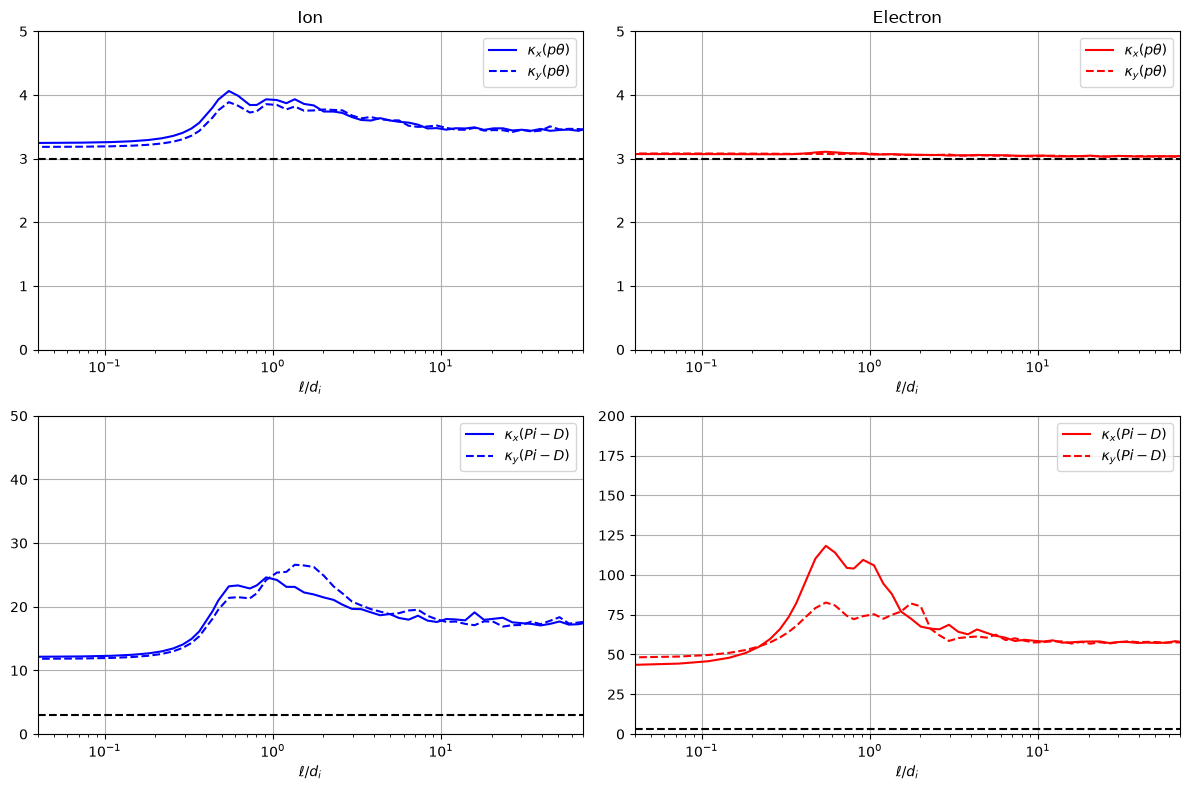

In [38]:
fig, ax = plt.subplots(2,2, figsize = (12, 8))

ax[0,1].set_title("Electron")
ax[0,0].set_title("Ion")


ax[0,1].plot(K_e.ell, K_e.ptheta_x, ls = '-', c = 'red', label= r"$\kappa_{x}(p \theta)$")
ax[0,1].plot(K_e.ell, K_e.ptheta_y, ls = '--', c = 'red', label=r"$\kappa_{y}(p \theta)$")

ax[0,0].plot(K_i.ell, K_i.ptheta_x, ls = '-', c = 'blue', label= r"$\kappa_{x}(p \theta)$")
ax[0,0].plot(K_i.ell, K_i.ptheta_y, ls = '--', c = 'blue', label=r"$\kappa_{y}(p \theta)$")

ax[1,1].plot(K_e.ell, K_e.PiD_x, ls = '-', c = 'red', label= r"$\kappa_{x}( Pi-D)$")
ax[1,1].plot(K_e.ell, K_e.PiD_y, ls = '--', c = 'red', label=r"$\kappa_{y}( Pi-D)$")

ax[1,0].plot(K_i.ell, K_i.PiD_x, ls = '-', c = 'blue', label= r"$\kappa_{x}(Pi-D)$")
ax[1,0].plot(K_i.ell, K_i.PiD_y, ls = '--', c = 'blue', label=r"$\kappa_{y}(Pi-D)$")


ax[1,0].set_ylim(0, 50)
ax[1,1].set_ylim(0, 200)


for i in range(2):
    for j in range(2):
        ax[i,j].grid(True)


for i in range(2):
        ax[0,i].axhline(3, color="k", linestyle="--")
        ax[0,i].set(xscale="log", xlabel=r"$\ell/d_i$")
        ax[0,i].set_ylim(0, 5)
        ax[0,i].set_xlim(4e-2, 7e1)
        ax[0,i].legend()

for i in range(2):
        ax[1,i].axhline(3, color="k", linestyle="--")
        ax[1,i].set(xscale="log", xlabel=r"$\ell/d_i$")
        ax[1,i].set_xlim(4e-2, 7e1)
        ax[1,i].legend(loc='upper right')
fig.tight_layout()
fig.savefig("../fig/SD_kurtosis.png")